# Правило против модели: качество ранжирования

Сравниваем правило давности и логистическую регрессию на точке проверки 2026-01-01. Решение «правило или модель» здесь не принимается: его примут по ожидаемой прибыли на следующем шаге.

Обучение — точки обучения без клиентов, у которых окно пересекается с кампанией (`excluded_campaign`). Точка проверки не участвует в подборе параметров. `got_campaign` и `purchases_back300` не используются.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

from churn.model import (
    TOP_K, bootstrap, boosting_needed, calibration, design, fit_boosting, fit_logreg, fit_rule, load,
    metrics, rule_score, split,
)

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "lines.linewidth": 2})
COLORS = {"правило": "#eb6834", "логрегрессия": "#2a78d6", "бустинг": "#1baf7a"}

df = load()
train, test = split(df)
y = test["churn"].to_numpy()
print(f"обучение: {len(train)} строк, {train['point'].nunique()} точек, доля churn {train['churn'].mean():.3f}")
print(f"проверка: {len(test)} клиентов, доля churn {y.mean():.3f}")

обучение: 170061 строк, 15 точек, доля churn 0.342
проверка: 20779 клиентов, доля churn 0.353


## Правило

Повторные покупатели: риск, если `days_since_last > k × median_gap`; одна покупка: риск, если `days_since_last > X`. Пара (k, X) выбирается по максимуму F1 на всех строках обучения вместе. Для ранжирования используется оценка `days_since_last / (k × median_gap)` или `days_since_last / X`.

In [2]:
grid, best = fit_rule(train)
k, x = best["k"], best["x"]
print(f"k = {k}, X = {x:.0f}, F1 на обучении = {best['f1']:.4f}")
grid.pivot(index="k", columns="x", values="f1")

k = 1.5, X = 30, F1 на обучении = 0.6973


x,30,45,60,90
k,,,,
1.5,0.697,0.666,0.619,0.490
2.0,0.692,0.658,0.607,0.464
2.5,0.673,0.635,0.580,0.426
3.0,0.650,0.609,0.551,0.387
4.0,0.615,0.569,0.506,0.328


Лучшая пара лежит на краю сетки: наименьшие k и X. При доле churn около 0.38 F1 выгодно отмечать больше клиентов.

## Логистическая регрессия

Числовые признаки стандартизованы, `main_category`, `channel`, `region` — one-hot. Пустые `median_gap`, `last_gap`, `recency_to_median_gap` заполнены нулём, добавлен флаг одной покупки. C подбирается по PR-AUC, каждая точка обучения — отдельный фолд.

In [3]:
search = fit_logreg(train)
cv = pd.DataFrame(search.cv_results_)[["param_logisticregression__C", "mean_test_score", "std_test_score"]]
cv.columns = ["C", "PR-AUC", "std"]
print("выбрано C =", search.best_params_["logisticregression__C"])
cv

выбрано C = 31.622776601683793


,C,PR-AUC,std
0,0.001,0.789,0.191
1,0.003,0.790,0.191
2,0.010,0.790,0.191
3,0.032,0.790,0.191
4,0.100,0.790,0.191
5,0.316,0.790,0.191
6,1.000,0.790,0.191
7,3.162,0.790,0.191
8,10.000,0.790,0.191
9,31.623,0.790,0.191


PR-AUC по фолдам почти не зависит от C: признаков мало, строк много, регуляризация почти ничего не меняет.

## Метрики на точке проверки

Top-k: k = 1 000, 2 000, 4 000 и k = числу клиентов, которых правило отмечает как риск. База для сравнения точности — доля churn.

In [4]:
scores = {"правило": rule_score(test, k, x), "логрегрессия": search.predict_proba(design(test))[:, 1]}
k_rule = int((scores["правило"] > 1).sum())
ks = (*TOP_K, k_rule)
print(f"правило отмечает {k_rule} клиентов, база точности {y.mean():.3f}")
pd.DataFrame({name: metrics(y, s, ks) for name, s in scores.items()})

правило отмечает 6263 клиентов, база точности 0.353


,правило,логрегрессия
pr_auc,0.758,0.799
roc_auc,0.813,0.850
precision@1000,0.940,0.956
recall@1000,0.128,0.130
precision@2000,0.931,0.952
recall@2000,0.254,0.259
precision@4000,0.866,0.878
recall@4000,0.472,0.479
precision@6263,0.745,0.763
recall@6263,0.635,0.651


Разница логрегрессия − правило, 95% бутстреп-интервал (1 000 повторов по клиентам).

In [5]:
boot = bootstrap(y, scores["правило"], scores["логрегрессия"], ks)
boot

,diff,lo,hi
pr_auc,0.041,0.035,0.047
precision@1000,0.016,0.008,0.030
precision@2000,0.020,0.013,0.029
precision@4000,0.013,0.006,0.020
precision@6263,0.019,0.011,0.025


## Градиентный бустинг

Обучаем, только если логистическая регрессия лучше правила по PR-AUC хотя бы на 0.02 и интервал разницы не включает ноль. Параметры бустинга подбираются так же: по PR-AUC, точка обучения — фолд.

In [6]:
print("условие выполнено:", boosting_needed(boot))
if boosting_needed(boot):
    hgb = fit_boosting(train)
    print("параметры:", {k_.split("__")[1]: v for k_, v in hgb.best_params_.items()})
    scores["бустинг"] = hgb.predict_proba(design(test))[:, 1]
    boot_hgb = pd.concat({
        "бустинг − правило": bootstrap(y, scores["правило"], scores["бустинг"], ks),
        "бустинг − логрегрессия": bootstrap(y, scores["логрегрессия"], scores["бустинг"], ks),
    }, axis=1)
    display(pd.DataFrame({name: metrics(y, s, ks) for name, s in scores.items()}))
    display(boot_hgb)

условие выполнено: True


параметры: {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 31}


,правило,логрегрессия,бустинг
pr_auc,0.758,0.799,0.808
roc_auc,0.813,0.850,0.846
precision@1000,0.940,0.956,0.988
recall@1000,0.128,0.130,0.135
precision@2000,0.931,0.952,0.969
recall@2000,0.254,0.259,0.264
precision@4000,0.866,0.878,0.893
recall@4000,0.472,0.479,0.486
precision@6263,0.745,0.763,0.769
recall@6263,0.635,0.651,0.656


бустинг − правило               бустинг − логрегрессия         \
                            diff     lo     hi                   diff     lo   
pr_auc                     0.051  0.044  0.057                  0.009  0.006   
precision@1000             0.048  0.035  0.065                  0.032  0.021   
precision@2000             0.037  0.029  0.049                  0.017  0.011   
precision@4000             0.027  0.019  0.034                  0.015  0.007   
precision@6263             0.025  0.017  0.032                  0.006  0.001   

                       
                   hi  
pr_auc          0.013  
precision@1000  0.043  
precision@2000  0.026  
precision@4000  0.020  
precision@6263  0.012

## Сводная таблица

In [7]:
def ci(b):
    return b.apply(lambda r: f"{r['diff']:+.3f} [{r['lo']:+.3f}; {r['hi']:+.3f}]", axis=1)

table = pd.DataFrame({name: metrics(y, s, ks) for name, s in scores.items()}).round(3)
table["лр − правило"] = ci(boot)
if "бустинг" in scores:
    table["буст − правило"] = ci(boot_hgb["бустинг − правило"])
table.fillna("")

,правило,логрегрессия,бустинг,лр − правило,буст − правило
pr_auc,0.758,0.799,0.808,+0.041 [+0.035; +0.047],+0.051 [+0.044; +0.057]
roc_auc,0.813,0.850,0.846,,
precision@1000,0.940,0.956,0.988,+0.016 [+0.008; +0.030],+0.048 [+0.035; +0.065]
recall@1000,0.128,0.130,0.135,,
precision@2000,0.931,0.952,0.968,+0.020 [+0.013; +0.029],+0.037 [+0.029; +0.049]
recall@2000,0.254,0.259,0.264,,
precision@4000,0.866,0.878,0.893,+0.013 [+0.006; +0.020],+0.027 [+0.019; +0.034]
recall@4000,0.472,0.479,0.486,,
precision@6263,0.745,0.763,0.769,+0.019 [+0.011; +0.025],+0.025 [+0.017; +0.032]
recall@6263,0.635,0.651,0.656,,


## Кривые precision–recall

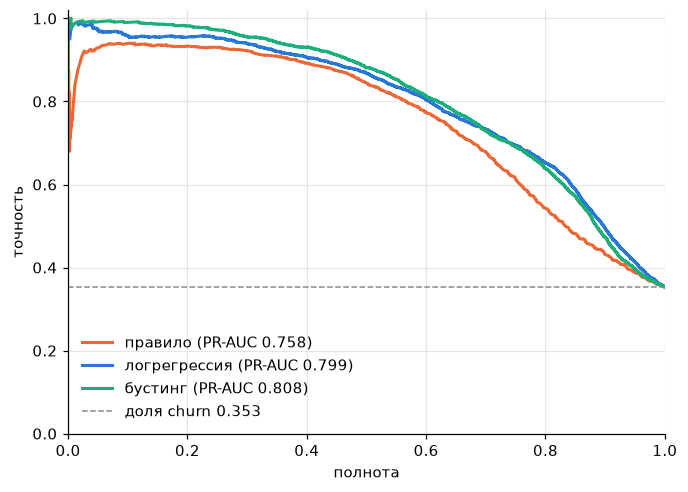

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y, s)
    ax.plot(r, p, color=COLORS[name], label=f"{name} (PR-AUC {table.loc['pr_auc', name]:.3f})")
ax.axhline(y.mean(), color="#8a8984", linewidth=1, linestyle="--", label=f"доля churn {y.mean():.3f}")
ax.set(xlabel="полнота", ylabel="точность", ylim=(0, 1.02), xlim=(0, 1))
ax.legend(frameon=False)
plt.show()

## Точность в top-k

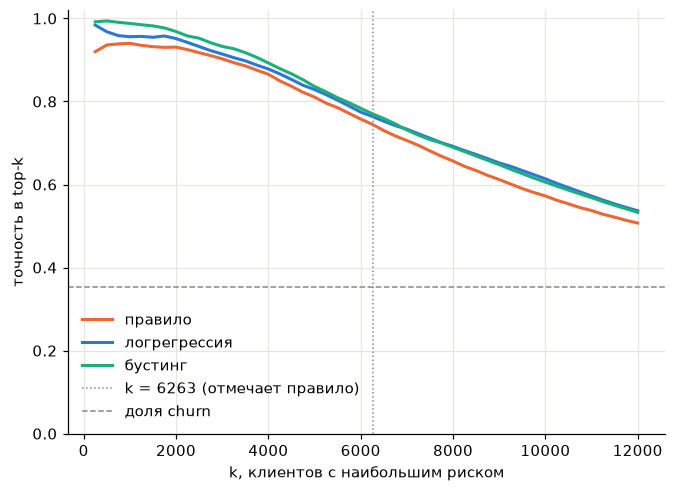

In [9]:
grid_k = np.arange(250, 12001, 250)
fig, ax = plt.subplots(figsize=(7, 5))
for name, s in scores.items():
    order = y[np.argsort(-s, kind="stable")]
    ax.plot(grid_k, np.cumsum(order)[grid_k - 1] / grid_k, color=COLORS[name], label=name)
ax.axvline(k_rule, color="#8a8984", linewidth=1, linestyle=":", label=f"k = {k_rule} (отмечает правило)")
ax.axhline(y.mean(), color="#8a8984", linewidth=1, linestyle="--", label="доля churn")
ax.set(xlabel="k, клиентов с наибольшим риском", ylabel="точность в top-k", ylim=(0, 1.02))
ax.legend(frameon=False)
plt.show()

## Калибровка

10 корзин равного размера по предсказанной вероятности.

логрегрессия                  бустинг                 
               n predicted actual       n predicted actual
bin                                                       
0           2078     0.040  0.100    2078     0.023  0.127
1           2078     0.061  0.089    2078     0.060  0.101
2           2078     0.080  0.104    2078     0.071  0.102
3           2078     0.106  0.114    2078     0.084  0.101
4           2078     0.147  0.144    2078     0.118  0.149
5           2077     0.227  0.263    2077     0.195  0.247
6           2078     0.363  0.425    2078     0.345  0.394
7           2078     0.535  0.551    2078     0.507  0.550
8           2078     0.751  0.796    2078     0.774  0.797
9           2078     0.930  0.948    2078     0.962  0.966

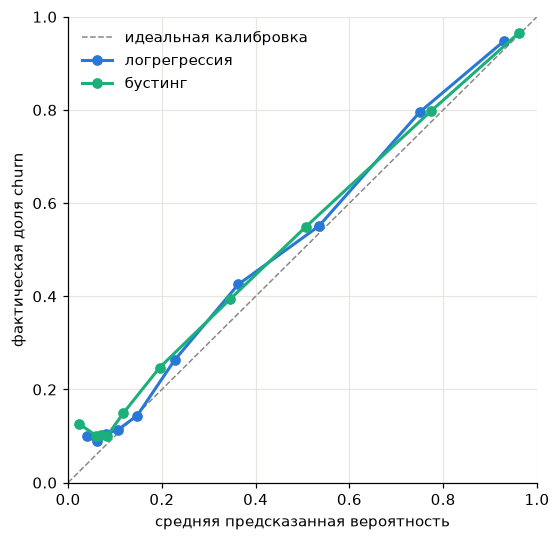

In [10]:
calib = {name: calibration(y, scores[name]) for name in scores if name != "правило"}
display(pd.concat(calib, axis=1))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="#8a8984", linewidth=1, linestyle="--", label="идеальная калибровка")
for name, c in calib.items():
    ax.plot(c["predicted"], c["actual"], color=COLORS[name], marker="o", markersize=6, label=name)
ax.set(xlabel="средняя предсказанная вероятность", ylabel="фактическая доля churn", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False)
plt.show()

## Одна покупка и повторные

In [11]:
rows = {}
for seg, m in {"одна покупка": test["purchases"].to_numpy() == 1, "повторные": test["purchases"].to_numpy() > 1}.items():
    for name, s in scores.items():
        mt = metrics(y[m], s[m], (2000,))
        rows[(seg, name)] = {"клиентов": m.sum(), "доля churn": y[m].mean(),
                             "pr_auc": mt["pr_auc"], "precision@2000": mt["precision@2000"]}
pd.DataFrame(rows).T

клиентов  доля churn  pr_auc  precision@2000
одна покупка правило         5480.0       0.675   0.883           0.925
             логрегрессия    5480.0       0.675   0.889           0.928
             бустинг         5480.0       0.675   0.897           0.929
повторные    правило        15299.0       0.238   0.620           0.756
             логрегрессия   15299.0       0.238   0.663           0.787
             бустинг        15299.0       0.238   0.671           0.789

## Итог

Модели ранжируют лучше правила на всех k, и бутстреп-интервалы разниц не включают ноль. Основной выигрыш — у повторных покупателей; при одной покупке давность почти единственный сигнал, и модель почти не обходит правило. Модели занижают вероятность в нижних корзинах. Выбор между правилом и моделью — по ожидаемой прибыли при одинаковом размере кампании, на следующем шаге.